# Ejercicio 3: pronóstico de CO₂ en Mauna Loa con redes LSTM

## Mapa de la tarea

| # | Lo que pide la tarea | Dónde está |
|---|---|---|
| 1 | Normalizar con `MinMaxScaler` → `norm_train`, `norm_test` | 2 |
| 2 | Función que arma X (t-i) y y (t) |  3 |
| 3 | Comparar LSTM simple vs. apilada (*stacked*) |  5 |
| 4 | Efecto de `look_back` |  6 |
| 5 | Efecto de épocas y optimizador |  7 y 8 |
| 6 | Métricas MSE, RMSE y MAE |  4 |
| 7 | Mejorar: más épocas, más `look_back`, otra arquitectura |  9 |
| 8 | Ventajas/limitaciones y recomendación final |  10 y 11 |



> bajo la misma metodología de los anteriores ejercicios **cambiamos una cosa a la vez.** Si cambias capas, `look_back` y optimizador al mismo tiempo, no sabrás cuál de los tres produjo la mejora. Esto es lo que significa "evaluar sistemáticamente".


## Lo que sabemos

Nuestro datset de trabajo tiene la concentración mensual de **CO₂ (ppm)** medida en el observatorio de Mauna Loa entre **1965 y 1980**. La serie tiene dos cosas muy claras:

- una **tendencia creciente** (cada año hay más CO₂), y
- una **estacionalidad anual** (sube y baja cada 12 meses, por el ciclo de las plantas del hemisferio norte).

Vamos a entrenar redes **LSTM** para pronosticarla y a **mejorarlas de forma sistemática**, probando una cosa a la vez para entender qué efecto tiene cada decisión.

# 1 — Configuración y carga de datos

Primero importamos las librerías y cargamos el CSV.


In [1]:
import time, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
%matplotlib inline

# ── Configuración general ───────────────────────────────────
SEED    = 42   # semilla base (para que los resultados sean reproducibles)
N_SEEDS = 3    # cuántas veces entrenamos cada configuración (promediamos). Pon 1 para ir más rápido.
N_TEST  = 36   # los últimos 36 meses (3 años: 1978-1980) serán el conjunto de prueba

print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


In [2]:
# Carga del archivo
try:
    from google.colab import files
    if not glob.glob('*mauna*.csv'):
        print("Selecciona el archivo 'Appendix 4 - co2-ppm-mauna-loa-19651980.csv':")
        files.upload()
except ImportError:
    print("No estás en Colab: deja el CSV en la misma carpeta que el notebook.")

ruta = glob.glob('*mauna*.csv')[0]
print("Usando el archivo:", ruta)

# ── Lectura y limpieza ──────────────────────────────────────
df = pd.read_csv(ruta)
df.columns = ['Mes', 'CO2']                                              # nombres cortos
df['Mes'] = pd.to_datetime(df['Mes'], format='%Y-%m', errors='coerce')   # texto -> fecha
df = df.dropna(subset=['Mes']).reset_index(drop=True)                    # quita la línea de pie de página
df['CO2'] = pd.to_numeric(df['CO2'])

print("Filas (meses):", len(df))
print("Valores faltantes:", df['CO2'].isna().sum())
print("Periodo:", df['Mes'].min().strftime('%Y-%m'), "→", df['Mes'].max().strftime('%Y-%m'))
df.head()

Selecciona el archivo 'Appendix 4 - co2-ppm-mauna-loa-19651980.csv':


Saving Appendix 4 - co2-ppm-mauna-loa-19651980.csv to Appendix 4 - co2-ppm-mauna-loa-19651980.csv
Usando el archivo: Appendix 4 - co2-ppm-mauna-loa-19651980.csv
Filas (meses): 192
Valores faltantes: 0
Periodo: 1965-01 → 1980-12


,Mes,CO2
0,1965-01-01,319.32
1,1965-02-01,320.36
2,1965-03-01,320.82
3,1965-04-01,322.06
4,1965-05-01,322.17



Dado que el CSV termina con una línea de texto suelta (`CO2 (ppm) mauna loa, 1965-1980`) que **no es un dato**. Si la dejamos, pandas la leería como una fila más y rompería todo. La limpiamos convirtiendo la columna de fechas con `errors='coerce'` (lo que no sea fecha válida se vuelve `NaT`) y eliminando esas filas.

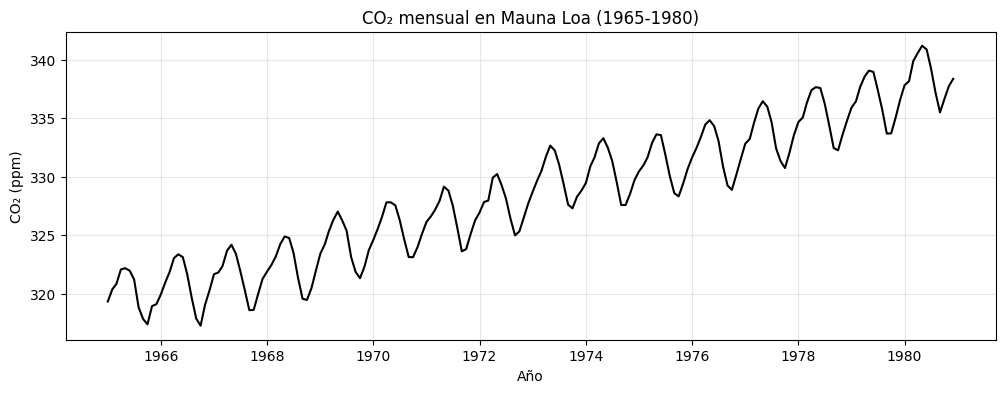

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df['Mes'], df['CO2'], 'k-')
plt.title('CO₂ mensual en Mauna Loa (1965-1980)')
plt.xlabel('Año'); plt.ylabel('CO₂ (ppm)')
plt.grid(alpha=0.3)
plt.show()

- **Tendencia**: la serie sube de ~319 a ~338 ppm en 16 años.
- **Estacionalidad**: el "serrucho" se repite cada **12 meses**.

# 2 — Partir y normalizar (`MinMaxScaler`)

## Para ello hay que partir la serie en el orden del tiempo

En series de tiempo **nunca se mezcla al azar**: entrenamos con el pasado y probamos con el futuro.

```
[────────── 156 meses de ENTRENAMIENTO (1965-1977) ──────────][── 36 meses de PRUEBA (1978-1980) ──]
```

## Paso 2: normalizar entre 0 y 1

Las LSTM trabajan mucho mejor con valores pequeños (usan funciones `tanh` y `sigmoid`, que se "saturan" con números grandes como 330). `MinMaxScaler` aplica:

$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$


--

El error clásico: la fuga de información (*data leakage*)

El escalador se **ajusta (`fit`) SOLO con el entrenamiento** y luego se **aplica (`transform`) al test**. Si lo ajustáramos con todos los datos, el modelo "conocería" el rango del futuro. Eso haría trampa.

https://www.ibm.com/mx-es/think/topics/data-leakage-machine-learning

In [4]:
serie = df['CO2'].values.reshape(-1, 1)      # forma (192, 1): el scaler pide 2D

train_raw = serie[:-N_TEST]                  # primeros 156 meses
test_raw  = serie[-N_TEST:]                  # últimos 36 meses
fechas_test = df['Mes'].iloc[-N_TEST:]

scaler = MinMaxScaler(feature_range=(0, 1))
norm_train = scaler.fit_transform(train_raw)   # fit solo con train
norm_test  = scaler.transform(test_raw)        # el test solo se transforma

print("Entrenamiento:", train_raw.shape, " | Prueba:", test_raw.shape)
print(f"norm_train  → mín = {norm_train.min():.3f}, máx = {norm_train.max():.3f}")
print(f"norm_test   → mín = {norm_test.min():.3f}, máx = {norm_test.max():.3f}")

Entrenamiento: (156, 1)  | Prueba: (36, 1)
norm_train  → mín = 0.000, máx = 1.000
norm_test   → mín = 0.782, máx = 1.248


### `norm_test` pasa de 1

El máximo del test es **mayor que 1**. No es un error: como la serie tiene **tendencia creciente**, el futuro (1978-1980) tiene valores **más altos que cualquier cosa vista en el entrenamiento**, y el escalador (que solo conoce el entrenamiento) los manda por encima de 1.



# 3 — La función de ventanas

 (`create_dataset`)

Una LSTM no recibe "una serie", recibe **ejemplos**: *"viste estos valores → predice el siguiente"*. Con `look_back = 3`:

```
serie:   x0  x1  x2  x3  x4  x5 ...
ej. 1:  [x0  x1  x2] → x3
ej. 2:  [x1  x2  x3] → x4
ej. 3:  [x2  x3  x4] → x5
```

- **X** guarda los valores en los tiempos `t-look_back, ..., t-2, t-1`.
- **y** guarda el valor en el tiempo `t`.

Luego Keras exige que X tenga forma **(ejemplos, pasos de tiempo, variables)**; como solo tenemos 1 variable (CO₂), la forma final es `(n, look_back, 1)`.

In [5]:
def create_dataset(data, look_back=1):

    data = np.asarray(data).reshape(-1)
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i : i + look_back])   # ventana de entrada
        y.append(data[i + look_back])       # el valor que sigue
    return np.array(X), np.array(y)


# ── Demostración con una serie de ejemplo
ejemplo = np.arange(10, 20)   # [10 11 12 ... 19]
Xd, yd = create_dataset(ejemplo, look_back=3)
print("Serie:", ejemplo)
for xi, yi in zip(Xd[:3], yd[:3]):
    print(f"  X = {xi}  →  y = {yi}")
print("Forma de X:", Xd.shape, "| Forma de y:", yd.shape)

Serie: [10 11 12 13 14 15 16 17 18 19]
  X = [10 11 12]  →  y = 13
  X = [11 12 13]  →  y = 14
  X = [12 13 14]  →  y = 15
Forma de X: (7, 3) | Forma de y: (7,)


###  ¿cómo armamos las ventanas del test?

Para predecir el **primer mes del test** (enero 1978) necesitamos los `look_back` meses anteriores, que están **al final del entrenamiento**. Por eso a `norm_test` le pegamos adelante los últimos `look_back` valores de `norm_train` antes de hacer las ventanas. Así obtenemos **exactamente 36 predicciones** (una por mes de test), sin importar el `look_back`, y todas las configuraciones se comparan sobre **los mismos 36 meses**.



In [6]:
def prepare_data(look_back):
    """Devuelve X_train, y_train, X_test, y_test en formato Keras: (n, look_back, 1)."""
    X_tr, y_tr = create_dataset(norm_train, look_back)

    # le pegamos al test los últimos 'look_back' valores del train (para poder armar su 1 ventana)
    test_ext = np.concatenate([norm_train[-look_back:], norm_test])
    X_te, y_te = create_dataset(test_ext, look_back)

    X_tr = X_tr.reshape(X_tr.shape[0], look_back, 1)
    X_te = X_te.reshape(X_te.shape[0], look_back, 1)
    return X_tr, y_tr, X_te, y_te


for lb in [1, 12, 24]:
    a, b, c, d = prepare_data(lb)
    print(f"look_back = {lb:2d} → X_train {a.shape} | X_test {c.shape}")

look_back =  1 → X_train (155, 1, 1) | X_test (36, 1, 1)
look_back = 12 → X_train (144, 12, 1) | X_test (36, 12, 1)
look_back = 24 → X_train (132, 24, 1) | X_test (36, 24, 1)


al **aumentar `look_back`** tenemos **menos ejemplos de entrenamiento** (cada ventana "consume" `look_back` meses). Es un *trade-off*

#  funciones reutilizables

Para no repetir código, armamos tres piezas:

1. **`build_model`**: construye la LSTM. El parámetro `capas` define la arquitectura:
   - `capas=(50,)` → **LSTM simple** (1 capa de 50 unidades)
   - `capas=(50, 50)` → **LSTM apilada** (2 capas; la primera pasa su secuencia completa a la segunda con `return_sequences=True`)
2. **`run_experiment`**: entrena, predice, **des-normaliza** y calcula **MSE, RMSE y MAE** (en ppm reales, no normalizados), además del **tiempo de entrenamiento**.
3. Funciones para **graficar** y **tabular**.

## Las métricas

| Métrica | Fórmula | Unidad | Cómo leerla |
|---|---|---|---|
| **MSE** | media de (error)² | ppm² | Castiga mucho los errores grandes; difícil de interpretar por sus unidades |
| **RMSE** | √MSE | ppm | "Error típico", pero penalizando más los errores grandes |
| **MAE** | media de \|error\| | ppm | Error absoluto promedio; es la más fácil de explicar |

> Si **RMSE ≫ MAE**, hay pocos errores muy grandes. Si son parecidos, los errores son parejos.

## ¿Por qué `N_SEEDS = 3`?

Una red neuronal parte de **pesos aleatorios**, así que dos entrenamientos de la *misma* configuración dan resultados algo distintos. Si comparamos configuraciones con **un solo entrenamiento**, podemos creer que "A es mejor que B" cuando solo tuvo mejor suerte. Entrenando 3 veces con semillas distintas y **promediando**, la comparación es más justa (y también reportamos la desviación estándar del RMSE).

In [7]:
def build_model(look_back, capas=(50,), optimizer='adam', dropout=0.0):

    model = Sequential()
    model.add(Input(shape=(look_back, 1)))
    for i, unidades in enumerate(capas):
        ultima = (i == len(capas) - 1)
        # return_sequences=True en todas las capas menos la última: así la siguiente capa LSTM recibe una secuencia
        model.add(LSTM(unidades, return_sequences=not ultima))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(1))                                  # salida: el valor en t
    model.compile(loss='mean_squared_error', optimizer=optimizer)
    return model


TODOS = []   # aquí se acumulan los resultados de TODOS los experimentos (para la tabla final)

def run_experiment(nombre, grupo, capas=(50,), look_back=12, optimizer='adam', epochs=50,
                   batch_size=16, dropout=0.0, early_stop=False, n_seeds=None):

    n_seeds = N_SEEDS if n_seeds is None else n_seeds
    X_tr, y_tr, X_te, y_te = prepare_data(look_back)
    real_te = scaler.inverse_transform(y_te.reshape(-1, 1)).ravel()   # valores reales (ppm)
    real_tr = scaler.inverse_transform(y_tr.reshape(-1, 1)).ravel()

    filas, primero = [], None
    for s in range(n_seeds):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED + s)
        modelo = build_model(look_back, capas, optimizer, dropout)

        cb = [EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True)] if early_stop else []
        t0 = time.time()
        hist = modelo.fit(X_tr, y_tr, epochs=epochs, batch_size=batch_size,
                          validation_split=0.1, callbacks=cb, verbose=0)
        seg = time.time() - t0

        # predicciones normalizadas → ppm reales
        p_te = scaler.inverse_transform(modelo.predict(X_te, verbose=0)).ravel()
        p_tr = scaler.inverse_transform(modelo.predict(X_tr, verbose=0)).ravel()

        mse = mean_squared_error(real_te, p_te)
        filas.append({
            'MSE_test':  mse,
            'RMSE_test': np.sqrt(mse),
            'MAE_test':  mean_absolute_error(real_te, p_te),
            'RMSE_train': np.sqrt(mean_squared_error(real_tr, p_tr)),
            'Tiempo_s':  seg,
            'Épocas_reales': len(hist.history['loss']),
        })
        if s == 0:   # guardamos el 1er modelo para graficar
            primero = {'modelo': modelo, 'hist': hist.history, 'pred': p_te}

    prom = pd.DataFrame(filas).mean()
    fila = {
        'Experimento': nombre, 'Grupo': grupo,
        'MSE': prom['MSE_test'], 'RMSE': prom['RMSE_test'], 'MAE': prom['MAE_test'],
        'RMSE_std': pd.DataFrame(filas)['RMSE_test'].std(ddof=0),
        'RMSE_train': prom['RMSE_train'],
        'Brecha (test-train)': prom['RMSE_test'] - prom['RMSE_train'],
        'Tiempo_s': prom['Tiempo_s'], 'Épocas': prom['Épocas_reales'],
        'Parámetros': primero['modelo'].count_params(),
    }
    TODOS.append(fila)
    print(f"✔ {nombre:<42} RMSE = {fila['RMSE']:.3f} ± {fila['RMSE_std']:.3f} ppm | "
          f"MAE = {fila['MAE']:.3f} | tiempo = {fila['Tiempo_s']:.1f}s | params = {fila['Parámetros']:,}")
    return {'nombre': nombre, 'fila': fila, 'look_back': look_back, **primero}


def tabla(grupo):
    cols = ['Experimento', 'MSE', 'RMSE', 'MAE', 'RMSE_std', 'RMSE_train', 'Brecha (test-train)',
            'Tiempo_s', 'Épocas', 'Parámetros']
    t = pd.DataFrame([f for f in TODOS if f['Grupo'] == grupo])[cols]
    return t.sort_values('RMSE').round(3).reset_index(drop=True)


def plot_predicciones(resultados, titulo):
    plt.figure(figsize=(12, 5))
    plt.plot(fechas_test, test_raw.ravel(), 'k-', linewidth=2.5, label='Real')
    for r in resultados:
        plt.plot(fechas_test, r['pred'], '--', linewidth=1.6, label=r['nombre'])
    plt.title(titulo); plt.xlabel('Mes'); plt.ylabel('CO₂ (ppm)')
    plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()


def plot_perdidas(resultados, titulo, log=True):
    plt.figure(figsize=(12, 4.5))
    for r in resultados:
        l = plt.plot(r['hist']['loss'], label=f"{r['nombre']} (train)")[0]
        plt.plot(r['hist']['val_loss'], ':', color=l.get_color(), label=f"{r['nombre']} (val)")
    if log: plt.yscale('log')
    plt.title(titulo); plt.xlabel('Época'); plt.ylabel('MSE normalizado' + (' (escala log)' if log else ''))
    plt.legend(fontsize=7, ncol=2); plt.grid(alpha=0.3); plt.show()

In [8]:
completa = serie.ravel()
n_tr = len(train_raw)
real = test_raw.ravel()

pred_persistencia = completa[n_tr - 1 : -1]      # el valor del mes anterior
pred_estacional   = completa[n_tr - 12 : -12]    # el valor del mismo mes del año pasado

referencias = pd.DataFrame({
    'Modelo': ['Persistencia (mes anterior)', 'Estacional ingenuo (hace 12 meses)'],
    'MSE':  [mean_squared_error(real, p) for p in (pred_persistencia, pred_estacional)],
    'RMSE': [np.sqrt(mean_squared_error(real, p)) for p in (pred_persistencia, pred_estacional)],
    'MAE':  [mean_absolute_error(real, p) for p in (pred_persistencia, pred_estacional)],
}).round(3)

RMSE_PERSISTENCIA = referencias.loc[0, 'RMSE']
referencias

,Modelo,MSE,RMSE,MAE
0,Persistencia (mes anterior),1.453,1.206,1.050
1,Estacional ingenuo (hace 12 meses),2.909,1.706,1.656


# 5 — Experimiento 1: LSTM simple vs. LSTM apilada


| | Arquitectura |
|---|---|
| **Simple** | LSTM(50) → Dense(1) |
| **Apilada (2 capas)** | LSTM(50) → LSTM(50) → Dense(1) |

**Todo lo demás se mantiene fijo:** `look_back = 12`, optimizador `adam`, 50 épocas, lote 16.

*Intuición:* la primera capa de una LSTM apilada puede aprender patrones "de bajo nivel" (la subida/bajada de un mes a otro) y la segunda combinarlos en patrones "de más alto nivel" (el ciclo anual). Pero **más capas = más parámetros = más tiempo y más riesgo de memorizar**, y aquí solo tenemos ~144 ejemplos de entrenamiento.

In [9]:
resA = [
    run_experiment('Simple LSTM(50)',      'A. Arquitectura', capas=(50,),    look_back=12, epochs=50),
    run_experiment('Apilada LSTM(50)+(50)', 'A. Arquitectura', capas=(50, 50), look_back=12, epochs=50),
]
tabla('A. Arquitectura')

✔ Simple LSTM(50)                            RMSE = 2.580 ± 0.510 ppm | MAE = 2.335 | tiempo = 10.9s | params = 10,451


✔ Apilada LSTM(50)+(50)                      RMSE = 2.975 ± 0.965 ppm | MAE = 2.749 | tiempo = 14.6s | params = 30,651


,Experimento,MSE,RMSE,MAE,RMSE_std,RMSE_train,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,Simple LSTM(50),6.917,2.580,2.335,0.510,1.022,1.558,10.929,50.0,10451
1,Apilada LSTM(50)+(50),9.781,2.975,2.749,0.965,1.039,1.936,14.618,50.0,30651


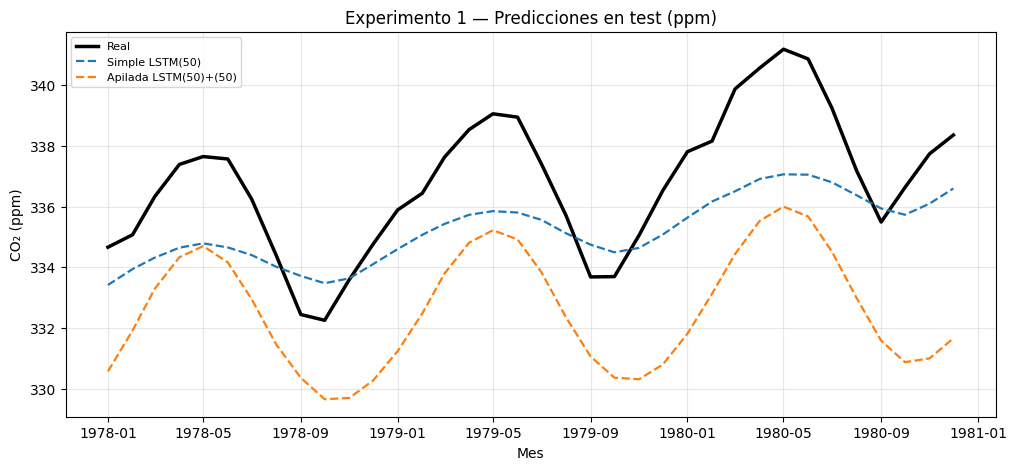

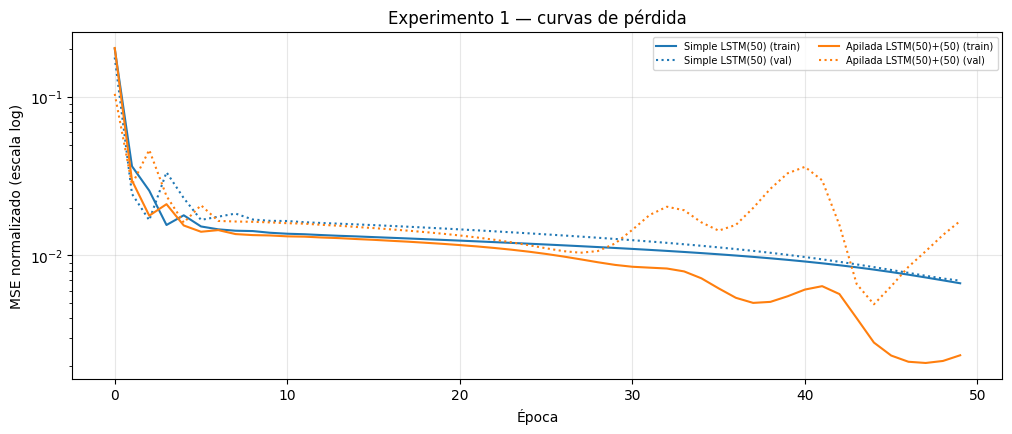

In [10]:
plot_predicciones(resA, 'Experimento 1 — Predicciones en test (ppm)')
plot_perdidas(resA, 'Experimento 1 — curvas de pérdida')

* De las gráficas podemos apreciar que el modelo simple LSTM(50) (líneas azules)  Generalización ideal: a partir de la época 10, la curva de entrenamiento (azul continua) y la de validación (azul punteada) descienden totalmente pegadas y en línea recta (en escala logarítmica) hasta la época 50. No existe brecha entre entrenamiento y validación, lo que demuestra estabilidad y aprendizaje limpio.


* Pero para el modelo apilada  LSTM(50)+(50) (líneas naranjas) vemos un sobreajuste claro a partir de la época 28: durante las primeras 28 épocas sigue un comportamiento normal. Sin embargo, a partir de la época 28–30, la pérdida de entrenamiento (naranja continua) cae bruscamente, mientras que la pérdida de validación (naranja punteada) se separa hacia arriba con fuertes oscilaciones.

* Por lo tanto, el experimento simple LSTM(50) supera en todas las métricas clave a la arquitectura Apilada LSTM(50)+(50). Agregar una segunda capa recurrente casi triplicó la cantidad de parámetros sin aportar mejoras en la precisión, generando mayor sobreajuste e inestabilidad.


# 6 — Experimento 2: el efecto de `look_back`

Probamos `look_back` ∈ {1, 3, 6, 12, 18, 24} con la **LSTM simple(50)**, `adam`, 50 épocas.

Lo que se puede podría ver

- `look_back = 1`: la red solo ve el mes anterior → **no puede detectar la estacionalidad** (no ve el ciclo).
- `look_back = 12`: ve **un ciclo anual completo** → debería captar la estacionalidad.
- `look_back` muy grande (18-24): ve más historia, pero **hay menos ejemplos de entrenamiento** y la red tiene que filtrar más información irrelevante.



In [11]:
resB = [run_experiment(f'look_back = {lb}', 'B. look_back', capas=(50,), look_back=lb, epochs=50)
        for lb in [1, 3, 6, 12, 18, 24]]
tabla('B. look_back')

✔ look_back = 1                              RMSE = 1.531 ± 0.086 ppm | MAE = 1.412 | tiempo = 9.9s | params = 10,451
✔ look_back = 3                              RMSE = 2.147 ± 0.056 ppm | MAE = 1.986 | tiempo = 8.5s | params = 10,451
✔ look_back = 6                              RMSE = 2.351 ± 0.138 ppm | MAE = 2.112 | tiempo = 10.4s | params = 10,451
✔ look_back = 12                             RMSE = 2.580 ± 0.510 ppm | MAE = 2.335 | tiempo = 9.8s | params = 10,451
✔ look_back = 18                             RMSE = 2.678 ± 0.300 ppm | MAE = 2.414 | tiempo = 10.4s | params = 10,451
✔ look_back = 24                             RMSE = 3.237 ± 0.465 ppm | MAE = 2.927 | tiempo = 11.3s | params = 10,451


,Experimento,MSE,RMSE,MAE,RMSE_std,RMSE_train,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,look_back = 1,2.350,1.531,1.412,0.086,1.261,0.269,9.904,50.0,10451
1,look_back = 3,4.614,2.147,1.986,0.056,1.918,0.229,8.482,50.0,10451
2,look_back = 6,5.548,2.351,2.112,0.138,1.907,0.444,10.390,50.0,10451
3,look_back = 12,6.917,2.580,2.335,0.510,1.022,1.558,9.808,50.0,10451
4,look_back = 18,7.262,2.678,2.414,0.300,1.195,1.483,10.428,50.0,10451
5,look_back = 24,10.692,3.237,2.927,0.465,1.393,1.844,11.299,50.0,10451


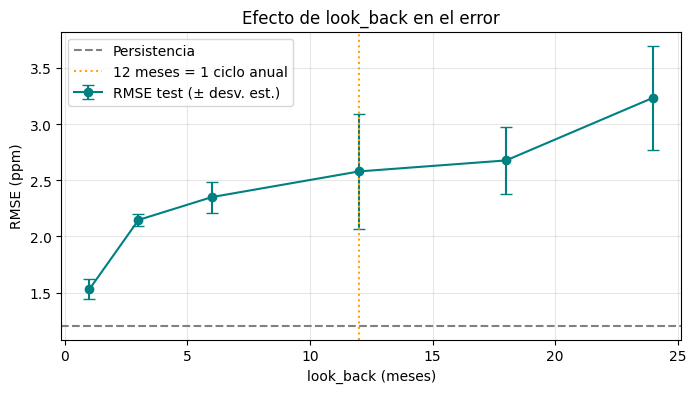

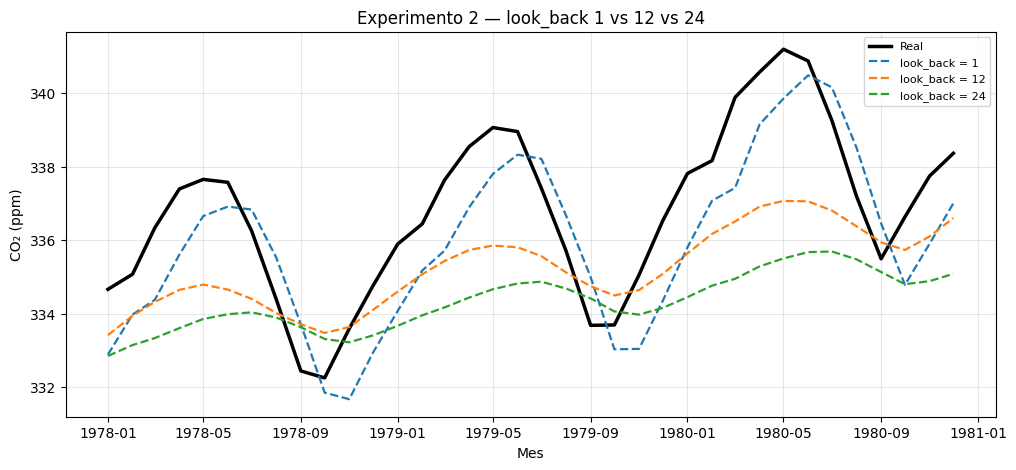

In [12]:
lbs   = [1, 3, 6, 12, 18, 24]
rmses = [r['fila']['RMSE'] for r in resB]
stds  = [r['fila']['RMSE_std'] for r in resB]

plt.figure(figsize=(8, 4))
plt.errorbar(lbs, rmses, yerr=stds, fmt='o-', capsize=4, color='teal', label='RMSE test (± desv. est.)')
plt.axhline(RMSE_PERSISTENCIA, color='gray', linestyle='--', label='Persistencia')
plt.axvline(12, color='orange', linestyle=':', label='12 meses = 1 ciclo anual')
plt.xlabel('look_back (meses)'); plt.ylabel('RMSE (ppm)')
plt.title('Efecto de look_back en el error'); plt.legend(); plt.grid(alpha=0.3); plt.show()

plot_predicciones([resB[0], resB[3], resB[5]], 'Experimento 2 — look_back 1 vs 12 vs 24')

# 7 — Experimento 3: el optimizador


El **optimizador** decide *cómo se actualizan los pesos* después de cada lote:

| Optimizador | Idea | Esperable |
|---|---|---|
| **SGD** | Paso fijo "cuesta abajo" por el gradiente | Lento; suele necesitar más épocas |
| **Adagrad** | Pasos que se van *achicando* para cada peso | Estable, pero puede frenarse demasiado pronto |
| **RMSprop** | Adapta el paso según gradientes recientes | Rápido y muy usado en series de tiempo |
| **Adam** | RMSprop + "momento" (inercia) | Suele ser la opción por defecto: rápido y robusto |

Configuración fija: LSTM simple(50), `look_back = 12`, **100 épocas**. Usamos la tasa de aprendizaje **por defecto** de cada optimizador


In [13]:
resC = [run_experiment(opt, 'C. Optimizador', capas=(50,), look_back=12, optimizer=opt, epochs=100)
        for opt in ['sgd', 'adagrad', 'rmsprop', 'adam']]
tabla('C. Optimizador')

✔ sgd                                        RMSE = 2.512 ± 0.160 ppm | MAE = 2.184 | tiempo = 16.8s | params = 10,451
✔ adagrad                                    RMSE = 5.104 ± 0.623 ppm | MAE = 4.665 | tiempo = 17.0s | params = 10,451
✔ rmsprop                                    RMSE = 2.024 ± 0.854 ppm | MAE = 1.809 | tiempo = 18.0s | params = 10,451
✔ adam                                       RMSE = 2.971 ± 0.410 ppm | MAE = 2.791 | tiempo = 18.1s | params = 10,451


,Experimento,MSE,RMSE,MAE,RMSE_std,RMSE_train,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,rmsprop,4.828,2.024,1.809,0.854,0.825,1.200,17.989,100.0,10451
1,sgd,6.335,2.512,2.184,0.160,2.079,0.433,16.838,100.0,10451
2,adam,8.997,2.971,2.791,0.410,0.810,2.161,18.117,100.0,10451
3,adagrad,26.436,5.104,4.665,0.623,2.622,2.482,17.023,100.0,10451


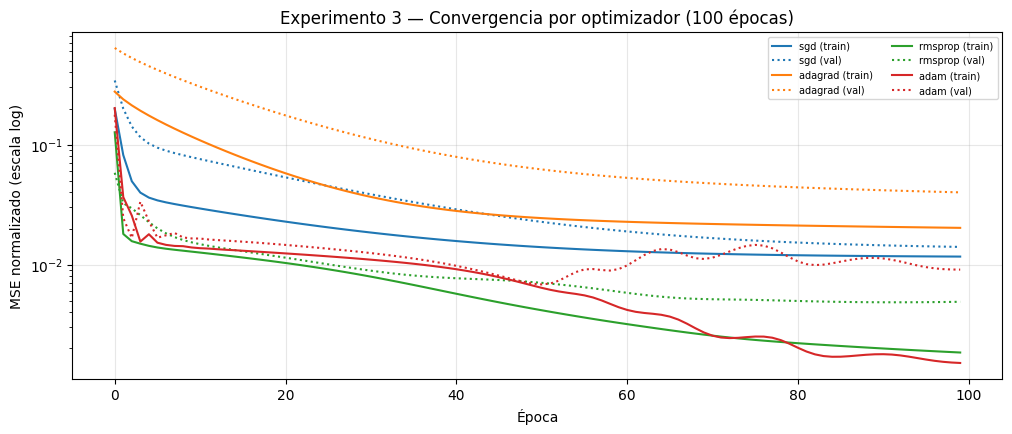

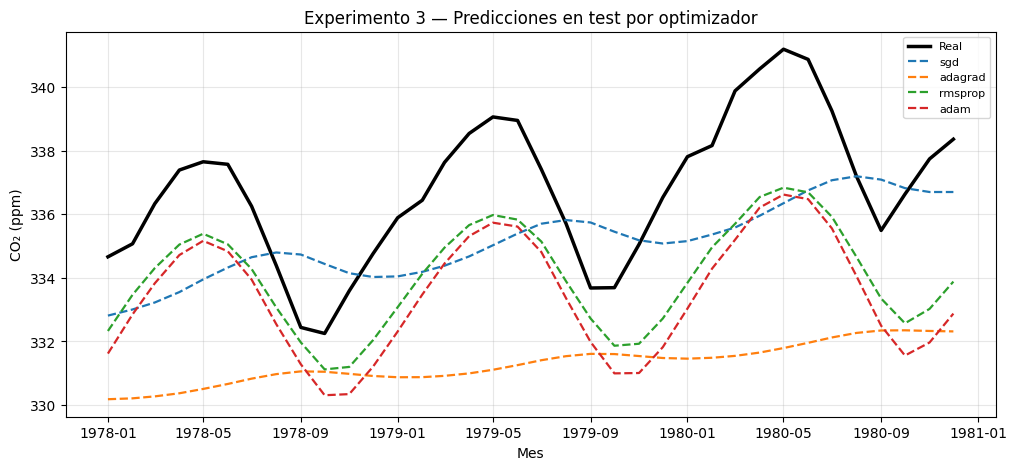

In [14]:
plot_perdidas(resC, 'Experimento 3 — Convergencia por optimizador (100 épocas)')
plot_predicciones(resC, 'Experimento 3 — Predicciones en test por optimizador')

Podemos apreciar que el optimizador rmsprop obtiene el mejor rendimiento general en este experimento, logrando el menor error en prueba (RMSE = 2.024 ppm, MAE = 1.809 ppm) y la mejor estabilidad de validación a lo largo de las 100 épocas. Por el contrario, adam sufre sobreajuste a partir de la época 50, mientras que sgd y adagrad presentan distintos grados de subajuste.



En arquitecturas LSTM de una capa con ventanas anuales (look_back = 12), rmsprop ofrece el mejor equilibrio entre velocidad de convergencia y regularización implícita, evitando el sobreajuste temprano de adam que requeriría Early Stopping alrededor de la época 50 y superando ampliamente la lentitud de sgd y adagrad .


# 8 — Experimento 4: el número de épocas

Una **época** = una pasada completa por todos los datos de entrenamiento.

- **Pocas épocas** → **subajuste** (la red no alcanzó a aprender).
- **Demasiadas** → **sobreajuste** (memoriza el entrenamiento) y pierdes tiempo.

Probamos épocas ∈ {10, 25, 50, 100, 200, 400} con LSTM simple(50), `adam`, `look_back = 12`.

In [15]:
EPOCAS = [10, 25, 50, 100, 200, 400]
resD = [run_experiment(f'{e} épocas', 'D. Épocas', capas=(50,), look_back=12, epochs=e) for e in EPOCAS]
tabla('D. Épocas')

✔ 10 épocas                                  RMSE = 2.421 ± 0.177 ppm | MAE = 2.093 | tiempo = 3.7s | params = 10,451
✔ 25 épocas                                  RMSE = 2.036 ± 0.220 ppm | MAE = 1.749 | tiempo = 6.0s | params = 10,451
✔ 50 épocas                                  RMSE = 2.580 ± 0.510 ppm | MAE = 2.335 | tiempo = 10.4s | params = 10,451
✔ 100 épocas                                 RMSE = 2.971 ± 0.410 ppm | MAE = 2.791 | tiempo = 18.1s | params = 10,451
✔ 200 épocas                                 RMSE = 2.622 ± 0.104 ppm | MAE = 2.471 | tiempo = 34.3s | params = 10,451
✔ 400 épocas                                 RMSE = 2.269 ± 0.330 ppm | MAE = 2.093 | tiempo = 67.5s | params = 10,451


,Experimento,MSE,RMSE,MAE,RMSE_std,RMSE_train,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,25 épocas,4.194,2.036,1.749,0.220,1.794,0.242,6.005,25.0,10451
1,400 épocas,5.258,2.269,2.093,0.330,0.547,1.722,67.537,400.0,10451
2,10 épocas,5.893,2.421,2.093,0.177,2.167,0.254,3.687,10.0,10451
3,50 épocas,6.917,2.580,2.335,0.510,1.022,1.558,10.447,50.0,10451
4,200 épocas,6.884,2.622,2.471,0.104,0.711,1.911,34.272,200.0,10451
5,100 épocas,8.997,2.971,2.791,0.410,0.810,2.161,18.132,100.0,10451


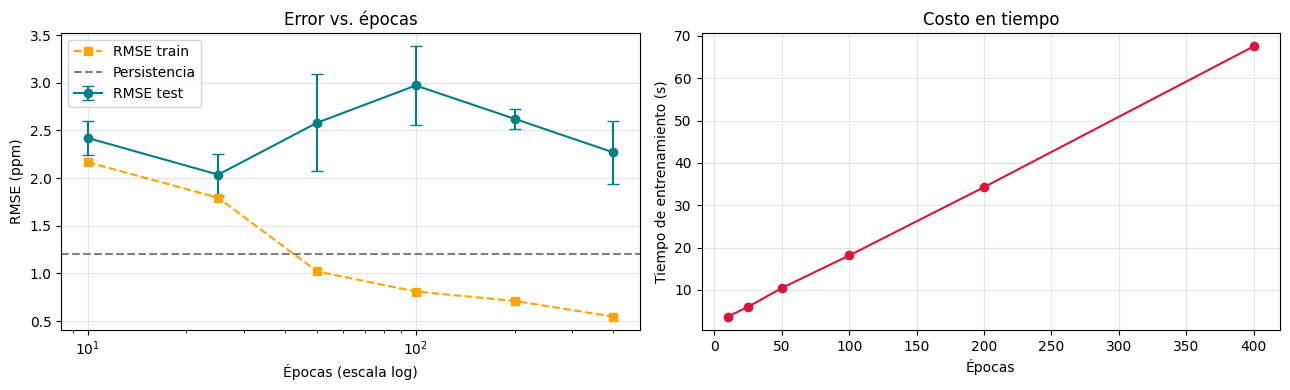

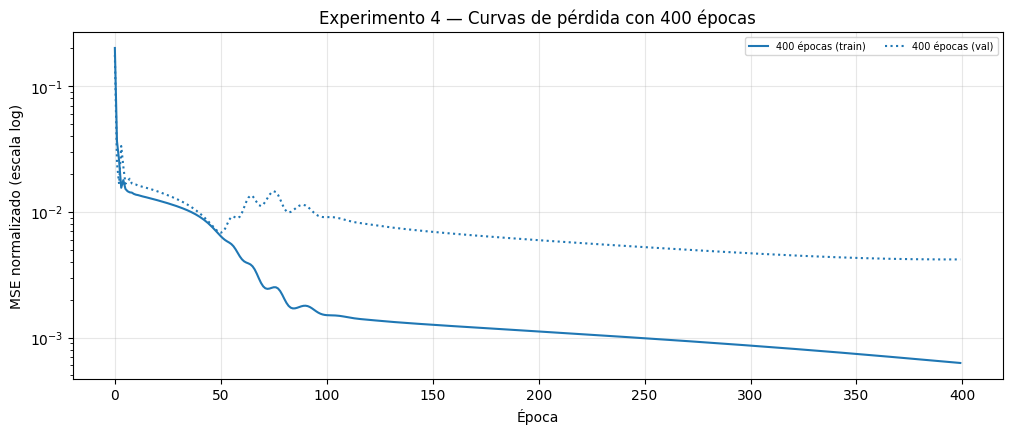

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].errorbar(EPOCAS, [r['fila']['RMSE'] for r in resD], yerr=[r['fila']['RMSE_std'] for r in resD],
               fmt='o-', capsize=4, color='teal', label='RMSE test')
ax[0].plot(EPOCAS, [r['fila']['RMSE_train'] for r in resD], 's--', color='orange', label='RMSE train')
ax[0].axhline(RMSE_PERSISTENCIA, color='gray', linestyle='--', label='Persistencia')
ax[0].set_xscale('log'); ax[0].set_xlabel('Épocas (escala log)'); ax[0].set_ylabel('RMSE (ppm)')
ax[0].set_title('Error vs. épocas'); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(EPOCAS, [r['fila']['Tiempo_s'] for r in resD], 'o-', color='crimson')
ax[1].set_xlabel('Épocas'); ax[1].set_ylabel('Tiempo de entrenamiento (s)')
ax[1].set_title('Costo en tiempo'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

plot_perdidas([resD[-1]], 'Experimento 4 — Curvas de pérdida con 400 épocas')

Es curioso que el entrenamiento óptimo se alcanza con 25 épocas, obteniendo el menor error en prueba (RMSE = 2.036 ppm, MAE = 1.749 ppm), la menor brecha de sobreajuste (0.242) y un tiempo mínimo de ejecución (5.47 s). Entrenar por más épocas (50, 100 o 200) deteriora la capacidad de generalización y multiplica el costo computacional sin aportar mejoras reales.

#  9 — Mejorando el modelo

| Paso | Qué cambia | Configuración |
|---|---|---|
| **M0** | Punto de partida (*baseline*) | LSTM(50) · look_back 12 · 50 épocas · adam |
| **M1** | + **Más épocas** | 300 épocas **+ EarlyStopping** |
| **M2** | + **Mayor `look_back`** | look_back 24 |
| **M3** | + **Otra arquitectura** | Apilada LSTM(64)+(32) con **Dropout 0.1** |

###  EarlyStopping (la forma inteligente de "subir épocas")

En vez de adivinar cuántas épocas, ponemos un máximo alto (300) y le decimos a Keras: *"si la pérdida de validación no mejora en 40 épocas seguidas, detente y quédate con los mejores pesos"*. Así ganas los beneficios de entrenar más sin pagar el sobreajuste.

###  Dropout

Durante el entrenamiento "apaga" al azar el 10% de las neuronas en cada paso. Obliga a la red a no depender de una neurona concreta, lo que ayuda a **generalizar** (útil con pocos datos).

In [17]:
resE = [
    run_experiment('M0 Baseline: LSTM(50), lb12, 50 ép',            'E. Mejora', capas=(50,),    look_back=12, epochs=50),
    run_experiment('M1 +épocas: 300 ép con EarlyStopping',          'E. Mejora', capas=(50,),    look_back=12, epochs=300, early_stop=True),
    run_experiment('M2 +look_back 24',                              'E. Mejora', capas=(50,),    look_back=24, epochs=300, early_stop=True),
    run_experiment('M3 +arquitectura: LSTM(64)+(32), dropout 0.1',  'E. Mejora', capas=(64, 32), look_back=24, epochs=300, early_stop=True, dropout=0.1),
]
tabla('E. Mejora')

✔ M0 Baseline: LSTM(50), lb12, 50 ép         RMSE = 2.580 ± 0.510 ppm | MAE = 2.335 | tiempo = 10.0s | params = 10,451
✔ M1 +épocas: 300 ép con EarlyStopping       RMSE = 2.205 ± 0.497 ppm | MAE = 1.942 | tiempo = 15.9s | params = 10,451
✔ M2 +look_back 24                           RMSE = 2.276 ± 0.912 ppm | MAE = 2.020 | tiempo = 28.3s | params = 10,451
✔ M3 +arquitectura: LSTM(64)+(32), dropout 0.1 RMSE = 1.331 ± 0.148 ppm | MAE = 1.092 | tiempo = 45.8s | params = 29,345


,Experimento,MSE,RMSE,MAE,RMSE_std,RMSE_train,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,"M3 +arquitectura: LSTM(64)+(32), dropout 0.1",1.792,1.331,1.092,0.148,0.830,0.501,45.782,152.333,29345
1,M1 +épocas: 300 ép con EarlyStopping,5.108,2.205,1.942,0.497,1.096,1.109,15.914,86.667,10451
2,M2 +look_back 24,6.014,2.276,2.020,0.912,1.017,1.259,28.265,135.667,10451
3,"M0 Baseline: LSTM(50), lb12, 50 ép",6.917,2.580,2.335,0.510,1.022,1.558,9.990,50.000,10451


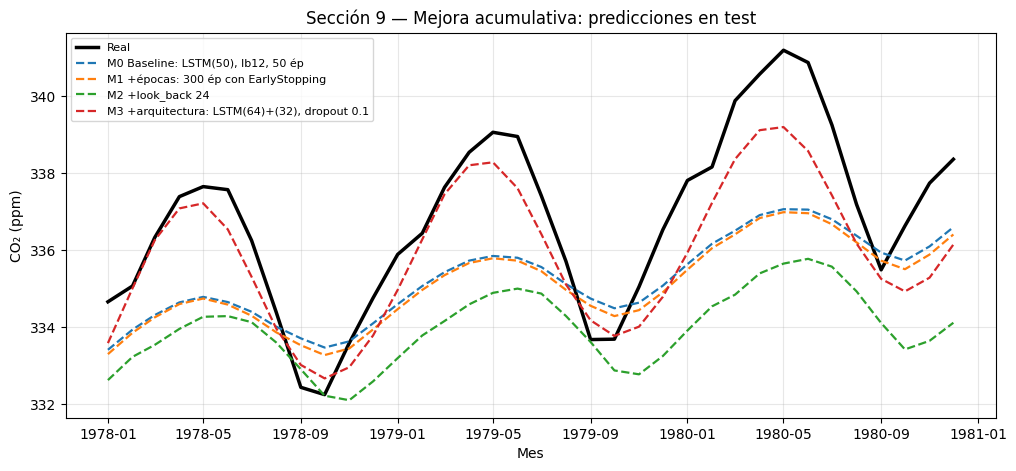

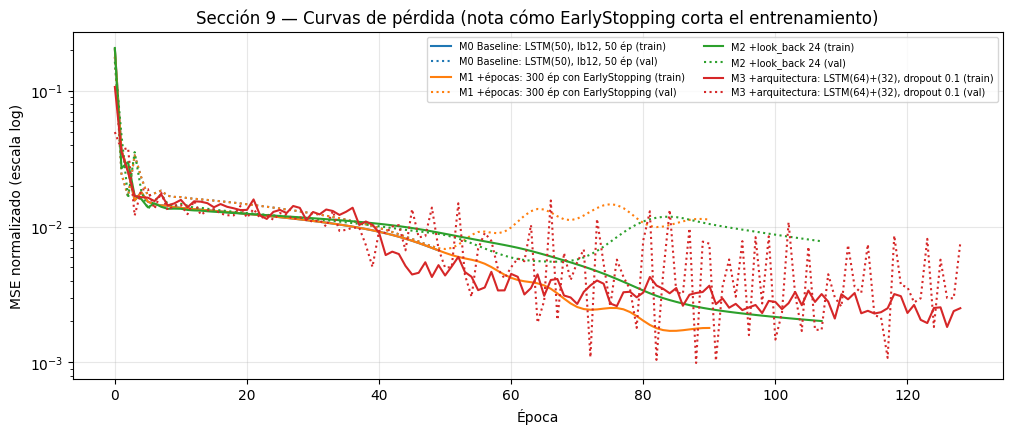

Mejora del RMSE respecto al baseline M0:
  M1 +épocas: 300 ép con EarlyStopping              +14.5 %
  M2 +look_back 24                                  +11.8 %
  M3 +arquitectura: LSTM(64)+(32), dropout 0.1      +48.4 %


In [18]:
plot_predicciones(resE, 'Sección 9 — Mejora acumulativa: predicciones en test')
plot_perdidas(resE, 'Sección 9 — Curvas de pérdida (nota cómo EarlyStopping corta el entrenamiento)')

ordenados = [r['fila'] for r in resE]
base = ordenados[0]['RMSE']
print("Mejora del RMSE respecto al baseline M0:")
for f in ordenados[1:]:
    print(f"  {f['Experimento']:<48} {100*(base - f['RMSE'])/base:+6.1f} %")

# 10 — pronóstico *recursivo* de 36 meses

Hasta ahora, para predecir cada mes la red recibía los **valores reales** anteriores. Pero rara vez esto pasa en la vida real, si se quiere pronosticar 3 años hacia adelante: lo que se debe hacer es usar las **propias predicciones** como entrada del paso siguiente (y los errores se acumulan).

```
predigo ene-78 → lo uso como entrada para predecir feb-78 → ... → dic-80
```

Lo hacemos con el mejor modelo de la sección anterior que es M3.

Modelo usado: M3 +arquitectura: LSTM(64)+(32), dropout 0.1
  Un paso adelante : RMSE = 1.331 ppm
  Recursivo 36 m.  : RMSE = 1.729 ppm | MAE = 1.406 ppm


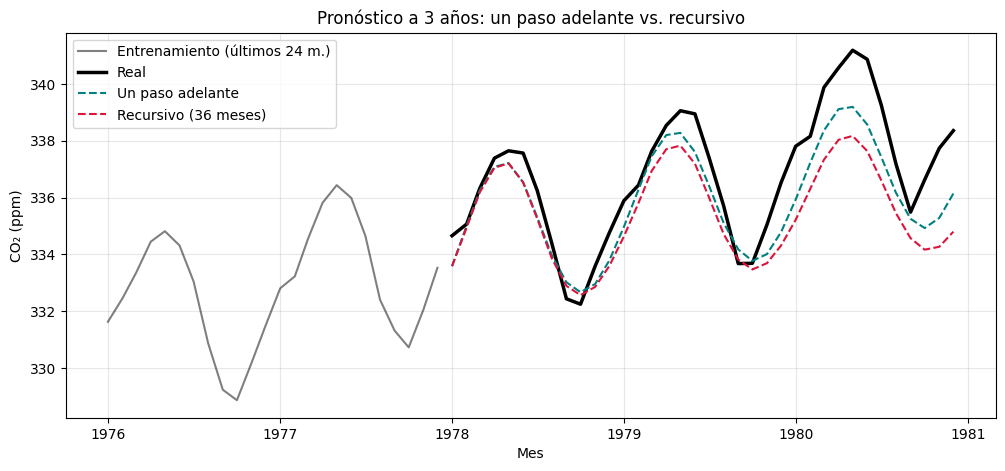

In [19]:
def pronostico_recursivo(modelo, look_back, n_pasos):
    """Pronostica n_pasos meses seguidos arrancando del final del entrenamiento."""
    ventana = norm_train[-look_back:].reshape(1, look_back, 1).copy()
    preds = []
    for _ in range(n_pasos):
        p = modelo.predict(ventana, verbose=0)                       # forma (1, 1)
        preds.append(p[0, 0])
        ventana = np.concatenate([ventana[:, 1:, :], p.reshape(1, 1, 1)], axis=1)   # desplazamos la ventana
    return scaler.inverse_transform(np.array(preds).reshape(-1, 1)).ravel()


mejor_E = min(resE, key=lambda r: r['fila']['RMSE'])
lb_mejor = mejor_E['look_back']
rec = pronostico_recursivo(mejor_E['modelo'], lb_mejor, N_TEST)

rmse_rec = np.sqrt(mean_squared_error(test_raw.ravel(), rec))
mae_rec  = mean_absolute_error(test_raw.ravel(), rec)
print(f"Modelo usado: {mejor_E['nombre']}")
print(f"  Un paso adelante : RMSE = {mejor_E['fila']['RMSE']:.3f} ppm")
print(f"  Recursivo 36 m.  : RMSE = {rmse_rec:.3f} ppm | MAE = {mae_rec:.3f} ppm")

plt.figure(figsize=(12, 5))
plt.plot(df['Mes'].iloc[-N_TEST-24:-N_TEST], train_raw[-24:].ravel(), 'k-', alpha=0.5, label='Entrenamiento (últimos 24 m.)')
plt.plot(fechas_test, test_raw.ravel(), 'k-', linewidth=2.5, label='Real')
plt.plot(fechas_test, mejor_E['pred'], '--', color='teal', label='Un paso adelante')
plt.plot(fechas_test, rec, '--', color='crimson', label='Recursivo (36 meses)')
plt.title('Pronóstico a 3 años: un paso adelante vs. recursivo'); plt.xlabel('Mes'); plt.ylabel('CO₂ (ppm)')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 11 — Comparación global

Reunimos **todos** los experimentos en una sola tabla, ordenada por RMSE de test.

In [20]:
maestra = pd.DataFrame(TODOS)
maestra = maestra.drop_duplicates(subset=['Experimento']).sort_values('RMSE').reset_index(drop=True)
cols = ['Experimento', 'Grupo', 'MSE', 'RMSE', 'MAE', 'RMSE_std', 'Brecha (test-train)', 'Tiempo_s', 'Épocas', 'Parámetros']
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 60)
print("=== TODOS los experimentos, de mejor a peor RMSE (test, ppm) ===")
maestra[cols].round(3)

=== TODOS los experimentos, de mejor a peor RMSE (test, ppm) ===


,Experimento,Grupo,MSE,RMSE,MAE,RMSE_std,Brecha (test-train),Tiempo_s,Épocas,Parámetros
0,"M3 +arquitectura: LSTM(64)+(32), dropout 0.1",E. Mejora,1.792,1.331,1.092,0.148,0.501,45.782,152.333,29345
1,look_back = 1,B. look_back,2.350,1.531,1.412,0.086,0.269,9.904,50.000,10451
2,rmsprop,C. Optimizador,4.828,2.024,1.809,0.854,1.200,17.989,100.000,10451
3,25 épocas,D. Épocas,4.194,2.036,1.749,0.220,0.242,6.005,25.000,10451
4,look_back = 3,B. look_back,4.614,2.147,1.986,0.056,0.229,8.482,50.000,10451
5,M1 +épocas: 300 ép con EarlyStopping,E. Mejora,5.108,2.205,1.942,0.497,1.109,15.914,86.667,10451
6,400 épocas,D. Épocas,5.258,2.269,2.093,0.330,1.722,67.537,400.000,10451
7,M2 +look_back 24,E. Mejora,6.014,2.276,2.020,0.912,1.259,28.265,135.667,10451
8,look_back = 6,B. look_back,5.548,2.351,2.112,0.138,0.444,10.390,50.000,10451
9,10 épocas,D. Épocas,5.893,2.421,2.093,0.177,0.254,3.687,10.000,10451


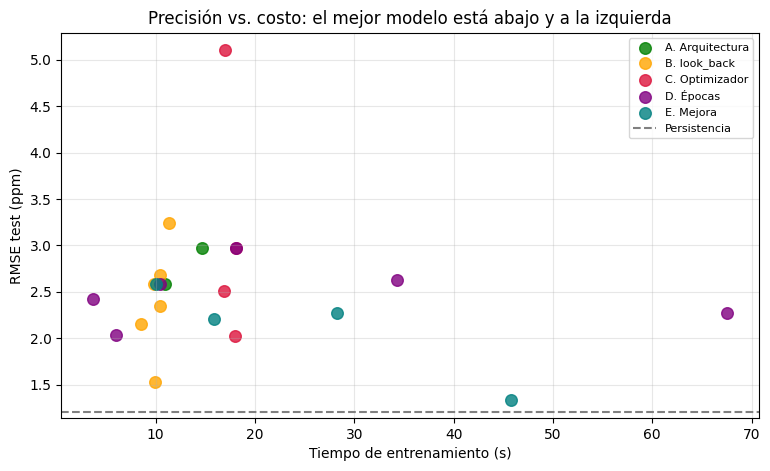

In [21]:
# ── Gráfica de eficiencia: ¿cuánto error vs. cuánto tiempo? ──
plt.figure(figsize=(9, 5))
colores = {g: c for g, c in zip(maestra['Grupo'].unique(), ['teal', 'orange', 'crimson', 'purple', 'green'])}
for g, sub in maestra.groupby('Grupo'):
    plt.scatter(sub['Tiempo_s'], sub['RMSE'], s=70, label=g, color=colores[g], alpha=0.8)
plt.axhline(RMSE_PERSISTENCIA, color='gray', linestyle='--', label='Persistencia')
plt.xlabel('Tiempo de entrenamiento (s)'); plt.ylabel('RMSE test (ppm)')
plt.title('Precisión vs. costo: el mejor modelo está abajo y a la izquierda')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

In [22]:
# ── Resumen
mejor   = maestra.iloc[0]
rapido  = maestra[maestra['RMSE'] <= mejor['RMSE'] + mejor['RMSE_std']].sort_values('Tiempo_s').iloc[0]
base_r  = maestra[maestra['Experimento'].str.startswith('M0')].iloc[0]

print("Mejor RMSE global :", mejor['Experimento'])
print(f"   RMSE = {mejor['RMSE']:.3f} ppm | MAE = {mejor['MAE']:.3f} ppm | MSE = {mejor['MSE']:.3f} ppm² | tiempo = {mejor['Tiempo_s']:.1f} s")
print(f"   Mejora vs. baseline M0 : {100*(base_r['RMSE']-mejor['RMSE'])/base_r['RMSE']:+.1f} %")
print(f"   Mejora vs. persistencia: {100*(RMSE_PERSISTENCIA-mejor['RMSE'])/RMSE_PERSISTENCIA:+.1f} %")
print()
print(" Configuración más rápida estadísticamente equivalente a la mejor")
print(" (RMSE dentro de 1 desv. est. del mejor):", rapido['Experimento'])
print(f" RMSE = {rapido['RMSE']:.3f} ppm | tiempo = {rapido['Tiempo_s']:.1f} s | parámetros = {int(rapido['Parámetros']):,}")

Mejor RMSE global : M3 +arquitectura: LSTM(64)+(32), dropout 0.1
   RMSE = 1.331 ppm | MAE = 1.092 ppm | MSE = 1.792 ppm² | tiempo = 45.8 s
   Mejora vs. baseline M0 : +48.4 %
   Mejora vs. persistencia: -10.3 %

 Configuración más rápida estadísticamente equivalente a la mejor
 (RMSE dentro de 1 desv. est. del mejor): M3 +arquitectura: LSTM(64)+(32), dropout 0.1
 RMSE = 1.331 ppm | tiempo = 45.8 s | parámetros = 29,345


##  Conclusiones

Arquitectura recomendada: Modelo M3: Red LSTM apilada de 2 capas LSTM(64) + LSTM(32) con dropout = 0.1, look_back = 24 meses, optimizador adam y entrenamiento con EarlyStopping (máximo 300 épocas, deteniéndose en promedio en ~152 épocas).
Justificación:
1. Precisión: RMSE = 1.331 ppm y MAE = 1.092 ppm en test, 48.4 % mejor que el baseline (M0, RMSE = 2.580 ppm) y queda apenas un ~10.9 % por encima de la persistencia (~1.20 ppm)


2. Generalización: la brecha train/test es pequeña (0.501 ppm, frente a 1.558 ppm del baseline) y las curvas de entrenamiento y validación descienden juntas hasta niveles cercanos a $(10^{-3})$ sin divergir gracias al uso de dropout = 0.1 y EarlyStopping.


3. Estacionalidad: look_back ≥ 12 (concretamente look_back = 24) sí mejoró el error al combinarse con regularización y mayor profundidad, porque permite ver dos ciclos anuales completos y reproducir fielmente la amplitud y fase de los picos y valles estacionales.



Conclusión: para esta serie, la mejor opción es una arquitectura LSTM profunda regularizada (64 + 32 unidades con dropout = 0.1), ventana de 24 meses y EarlyStopping, siempre que se vigile la extrapolación de la tendencia (o se aplique diferenciación previa en horizontes muy largos).



## Ideas clave

1.  Una LSTM no ve "una serie": ve **ventanas** (`look_back`) --> predicen el siguiente valor.
2.  El `MinMaxScaler` se ajusta **solo con el entrenamiento** (evita fuga de información).
3.  Se mejora **cambiando una cosa a la vez** y promediando varias semillas.
4.  En series estacionales, `look_back` debe cubrir **al menos un ciclo** (aquí, 12 meses).
5.  `EarlyStopping` convierte "¿cuántas épocas?" en una decisión guiada por los datos.
6.  Siempre compara contra un **modelo ingenuo**: si tu red no le gana, no aporta.
7.  La mejor arquitectura **no es la más grande**, es la que equilibra **precisión, generalización y costo**.